# Walmart — eksperymenty: warianty danych × modele

Każdy wariant danych z `src/datasets.py` jest trenowany na każdym modelu z `src/models.py`.
Zbiór testowy (ostatnie 8 tygodni) jest wspólny, więc wyniki są bezpośrednio porównywalne.
Wyniki zapisują się do `results/eksperymenty.csv`; policzone pary są pomijane przy ponownym uruchomieniu.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
%load_ext autoreload
%autoreload 2

from src.config import CAT, FEATURE_COLS, TARGET, setup_style
from src.data import load_raw, clean
from src.datasets import DATASETS, register, without
from src.models import MODELS
from src.experiment import run_experiments, load_results, pivot, plot_heatmap
from src import stats as st

setup_style()
df_clean = clean(load_raw(), verbose=False)

## 1. Dostępne warianty danych i modele

In [2]:
display(pd.DataFrame([{'dane': d.name, 'n_cech': len(d.features), 'opis': d.description}
                      for d in DATASETS.values()]).set_index('dane'))
print('Modele:', list(MODELS))

,n_cech,opis
dane,,
bazowy,27,Wszystkie cechy z notebooka bazowego
bez_historii,24,Bez lagów i średnich historycznych
bez_markdown,19,Bez cech promocyjnych
bez_makro,23,Bez zmiennych makro/pogodowych
dodatkowe_lagi,31,Bazowy + lag 2/4/52 i odchylenie kroczące
log_markdown,27,Bazowy z log1p na MarkDownach
bez_ujemnej_sprzedazy,27,Trening bez tygodni ze zwrotami netto


Modele: ['Regresja liniowa', 'Ridge', 'Drzewo decyzyjne', 'Random Forest', 'HistGradientBoosting', 'XGBoost', 'LightGBM']


## 2. Własne warianty

Nowy wariant danych lub model można dodać tutaj, bez ruszania `src/`:

In [3]:
# Przykład wariantu: bez cech kalendarzowych
# register('bez_kalendarza', without('Year', 'Month', 'WeekOfYear'), description='Bez roku/miesiąca/tygodnia')

# Przykład modelu: płytszy Random Forest
# from src.models import make_rf
# MODELS['RF płytki'] = lambda: make_rf(n_estimators=100, max_depth=10)

## 3. Uruchomienie siatki

`datasets=None` / `models=None` oznacza „wszystkie”. Pełna siatka trwa długo — można zacząć od podzbioru.
`force=True` przelicza od nowa pary już zapisane w CSV.

In [4]:
# Po `python run_all.py` wszystko jest policzone - ta komórka tylko wczytuje wyniki.
results, preds = run_experiments(
    datasets=None,          # np. ['bazowy', 'dodatkowe_lagi']
    models=None,            # np. ['Ridge', 'XGBoost']
    df_clean=df_clean,
    force=False,
    save_models=False,
)
results

[bazowy] Regresja liniowa       WMAE=   1888.7  R2=0.9773  (2s)


[bazowy] Ridge                  WMAE=   1888.7  R2=0.9773  (0s)


[bazowy] Drzewo decyzyjne       WMAE=   1626.5  R2=0.9764  (7s)


[bazowy] Random Forest          WMAE=   1506.9  R2=0.9822  (528s)


[bazowy] HistGradientBoosting   WMAE=   1435.7  R2=0.9846  (35s)


[bazowy] XGBoost                WMAE=   1374.0  R2=0.9859  (20s)


... (40 outputs left out)

[bez_ujemnej_sprzedazy] HistGradientBoosting   WMAE=   1389.4  R2=0.9851  (30s)


[bez_ujemnej_sprzedazy] XGBoost                WMAE=   1375.6  R2=0.9857  (21s)


[bez_ujemnej_sprzedazy] LightGBM               WMAE=   1371.1  R2=0.9857  (10s)


,dane,model,WMAE,MAE,RMSE,R2,czas_s,n_cech,n_train
0,dodatkowe_lagi,XGBoost,1201.226416,1143.193160,2376.369190,0.988104,20.9,31.0,397841.0
1,dodatkowe_lagi,LightGBM,1228.279545,1167.851526,2479.583689,0.987049,11.8,31.0,397841.0
2,dodatkowe_lagi,HistGradientBoosting,1234.759290,1170.412484,2523.710161,0.986583,30.6,31.0,397841.0
3,dodatkowe_lagi,Random Forest,1288.955502,1208.152224,2540.866292,0.986400,720.8,31.0,397841.0
4,bez_makro,XGBoost,1337.232369,1218.695679,2560.871546,0.986185,16.3,23.0,397841.0
5,bez_makro,LightGBM,1352.526429,1235.067211,2614.585595,0.985600,7.8,23.0,397841.0
6,bez_makro,HistGradientBoosting,1352.597775,1227.716007,2609.799788,0.985653,24.0,23.0,397841.0
7,bez_ujemnej_sprzedazy,LightGBM,1371.113548,1247.679362,2609.639869,0.985654,10.2,27.0,396621.0
8,bazowy,XGBoost,1373.969830,1249.220767,2586.158239,0.985911,19.6,27.0,397841.0
9,log_markdown,XGBoost,1373.969830,1249.220767,2586.158239,0.985911,17.5,27.0,397841.0


## 4. Porównanie

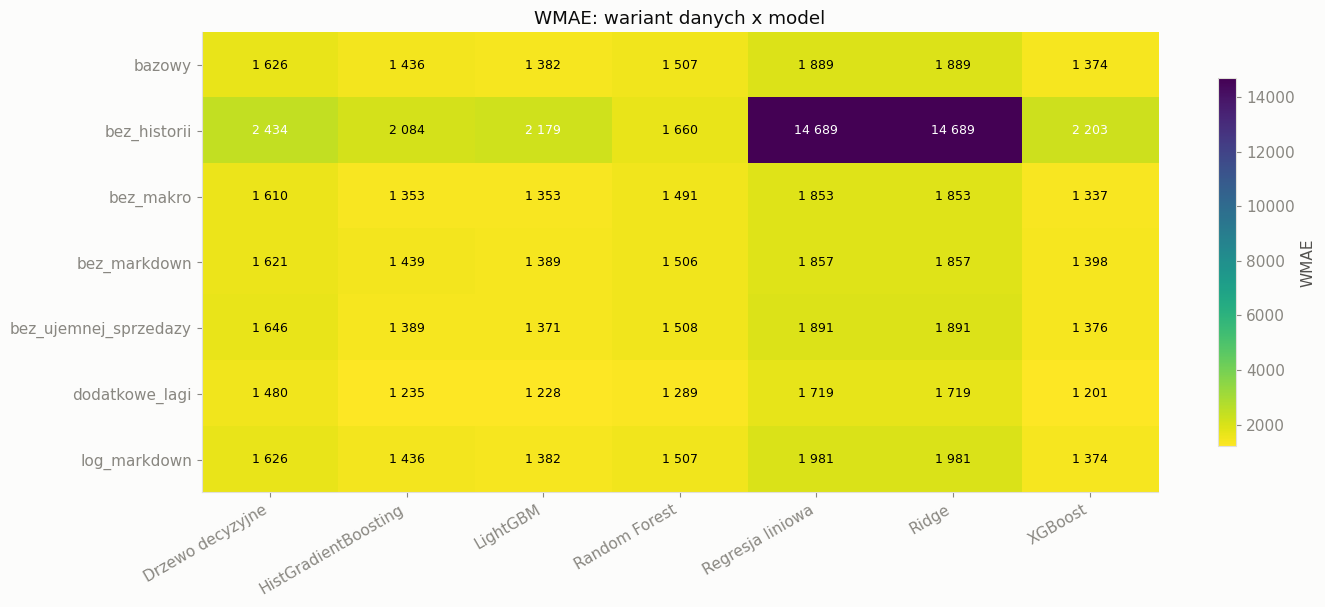

model,Drzewo decyzyjne,HistGradientBoosting,LightGBM,Random Forest,Regresja liniowa,Ridge,XGBoost
dane,,,,,,,
bazowy,1626.5,1435.7,1382.3,1506.9,1888.7,1888.7,1374.0
bez_historii,2433.6,2083.8,2178.7,1660.4,14688.8,14688.7,2202.5
bez_makro,1610.1,1352.6,1352.5,1490.7,1853.1,1853.1,1337.2
bez_markdown,1620.8,1438.8,1388.6,1505.6,1856.5,1856.5,1397.9
bez_ujemnej_sprzedazy,1646.1,1389.4,1371.1,1508.2,1890.8,1890.8,1375.6
dodatkowe_lagi,1479.6,1234.8,1228.3,1289.0,1718.8,1718.8,1201.2
log_markdown,1626.5,1435.7,1382.3,1507.0,1981.3,1981.3,1374.0


In [5]:
plot_heatmap(results, 'WMAE')
plt.tight_layout(); plt.show()
pivot(results, 'WMAE').round(1)

In [6]:
print('Najlepszy model dla każdego wariantu danych:')
display(results.loc[results.groupby('dane')['WMAE'].idxmin()].set_index('dane').sort_values('WMAE'))

print('Najlepszy wariant danych dla każdego modelu:')
display(results.loc[results.groupby('model')['WMAE'].idxmin()].set_index('model').sort_values('WMAE'))

Najlepszy model dla każdego wariantu danych:


,model,WMAE,MAE,RMSE,R2,czas_s,n_cech,n_train
dane,,,,,,,,
dodatkowe_lagi,XGBoost,1201.226416,1143.193160,2376.369190,0.988104,20.9,31.0,397841.0
bez_makro,XGBoost,1337.232369,1218.695679,2560.871546,0.986185,16.3,23.0,397841.0
bez_ujemnej_sprzedazy,LightGBM,1371.113548,1247.679362,2609.639869,0.985654,10.2,27.0,396621.0
bazowy,XGBoost,1373.969830,1249.220767,2586.158239,0.985911,19.6,27.0,397841.0
log_markdown,XGBoost,1373.969830,1249.220767,2586.158239,0.985911,17.5,27.0,397841.0
bez_markdown,LightGBM,1388.607741,1260.659275,2636.316860,0.985359,8.0,19.0,397841.0
bez_historii,Random Forest,1660.354805,1626.819482,3237.371003,0.977923,269.2,24.0,397841.0


Najlepszy wariant danych dla każdego modelu:


,dane,WMAE,MAE,RMSE,R2,czas_s,n_cech,n_train
model,,,,,,,,
XGBoost,dodatkowe_lagi,1201.226416,1143.193160,2376.369190,0.988104,20.9,31.0,397841.0
LightGBM,dodatkowe_lagi,1228.279545,1167.851526,2479.583689,0.987049,11.8,31.0,397841.0
HistGradientBoosting,dodatkowe_lagi,1234.759290,1170.412484,2523.710161,0.986583,30.6,31.0,397841.0
Random Forest,dodatkowe_lagi,1288.955502,1208.152224,2540.866292,0.986400,720.8,31.0,397841.0
Drzewo decyzyjne,dodatkowe_lagi,1479.561911,1376.699074,3112.952703,0.979587,9.6,31.0,397841.0
Ridge,dodatkowe_lagi,1718.837443,1658.855643,3226.601459,0.978069,0.4,31.0,397841.0
Regresja liniowa,dodatkowe_lagi,1718.842236,1658.866452,3226.625276,0.978069,0.7,31.0,397841.0


## 5. Czy różnica jest istotna statystycznie?

Test Wilcoxona dla par: porównanie błędów bezwzględnych dwóch najlepszych konfiguracji
na tych samych obserwacjach testowych. H0: mediany błędów są równe.
(Predykcje wczytywane z `results/predykcje/`.)

In [ ]:
from scipy.stats import wilcoxon
from src.experiment import load_preds

# Dwie najlepsze konfiguracje wg WMAE - predykcje wczytywane z results/predykcje/
best2 = load_results().sort_values('WMAE')[['dane', 'model']].head(2).values.tolist()
pa, pb = (load_preds(d, m) for d, m in best2)
assert (pa[['Store', 'Dept', 'Date']].values == pb[['Store', 'Dept', 'Date']].values).all()
ea, eb = (pa['y_true'] - pa['y_pred']).abs(), (pb['y_true'] - pb['y_pred']).abs()
stat, p = wilcoxon(ea, eb)
print(f'{best2[0]} vs {best2[1]}\nMAE: {ea.mean():.1f} vs {eb.mean():.1f}   Wilcoxon p = {p:.3g}'
      f'   -> różnica {"istotna" if p < 0.05 else "nieistotna"}')

## 6. Strojenie hiperparametrów

Strojenie uruchamiane jest skryptem (trwa godziny), np.:
```
python run_all.py --fresh        # wszystko: siatka + strojenie (CPU i GPU równolegle)
python run_tuning.py LightGBM    # albo pojedynczy model
```
Losowe przeszukiwanie (`src/tuning.py`), ocena: średni WMAE z 3 okien walidacyjnych po 8 tygodni
z końca zbioru **treningowego** (expanding window). Zbiór testowy nie bierze udziału w wyborze
parametrów — dopiero na końcu porównujemy na nim wersję domyślną i strojoną.

In [ ]:
from src.tuning import TUNING_DIR, best_params, register_tuned

tuned = {p.stem.split('__', 1)[1].replace('_', ' '): pd.read_csv(p)
         for p in sorted(TUNING_DIR.glob('bazowy__*.csv'))}
for name, tr in tuned.items():
    print(f'{name}: {len(tr)} prób, najlepszy WMAE (walidacja) = {tr["WMAE_sr"].min():.1f}')
    display(pd.Series(best_params(name, 'bazowy'), name='najlepsze parametry').to_frame())

In [ ]:
# Przebieg przeszukiwania: wynik każdej próby i najlepszy dotąd
fig, axes = plt.subplots(1, len(tuned), figsize=(5 * len(tuned), 3.8), squeeze=False)
for ax, (name, tr) in zip(axes[0], tuned.items()):
    tr = tr.sort_values('proba')
    ax.scatter(tr['proba'] + 1, tr['WMAE_sr'], color=CAT[0], s=18, label='próba')
    ax.plot(tr['proba'] + 1, tr['WMAE_sr'].cummin(), color=CAT[1], lw=2, label='najlepszy dotąd')
    ax.set_title(name); ax.set_xlabel('nr próby'); ax.set_ylabel('WMAE (walidacja)')
    ax.set_ylim(top=tr['WMAE_sr'].quantile(0.9) * 1.05)
axes[0][0].legend()
plt.tight_layout(); plt.show()

In [ ]:
# Domyślne vs strojone - zbiór testowy
res = load_results()
res = res[res['dane'] == 'bazowy']
rows = []
for name in tuned:
    d = res[res['model'] == name]
    t = res[res['model'] == f'{name} (strojony)']
    if len(d) and len(t):
        rows.append({'model': name, 'WMAE domyślny': d['WMAE'].iat[0], 'WMAE strojony': t['WMAE'].iat[0],
                     'R2 domyślny': d['R2'].iat[0], 'R2 strojony': t['R2'].iat[0]})
cmp = pd.DataFrame(rows).set_index('model')
cmp['poprawa %'] = 100 * (1 - cmp['WMAE strojony'] / cmp['WMAE domyślny'])
cmp.round(3)

In [ ]:
res.sort_values('WMAE')[['model', 'WMAE', 'MAE', 'RMSE', 'R2', 'czas_s']].reset_index(drop=True)

### Sieć z embeddingami — krzywe uczenia i nauczone reprezentacje działów

Ponowny trening strojonej sieci (kilka minut na GPU), żeby obejrzeć jej wnętrze.

In [ ]:
from src.experiment import prepare
from src.evaluation import metrics

name = register_tuned('Sieć z embeddingami', 'bazowy')
X_train, y_train, X_test, test = prepare(DATASETS['bazowy'], df_clean)
net = MODELS[name]().fit(X_train.fillna(X_train.median()), y_train)
print(metrics(test[TARGET], net.predict(X_test.fillna(X_train.median())), test['IsHoliday']))
print(net.model_)

ax = net.history_.plot(x='epoka', y=['train_loss', 'val_loss'], color=CAT[:2], figsize=(7, 3.5))
ax.set_ylabel('strata (standaryzowana)'); ax.set_title('Krzywe uczenia')
plt.show()

In [ ]:
# Embeddingi działów zrzutowane PCA na 2D - działy blisko siebie sieć traktuje podobnie
from sklearn.decomposition import PCA

E = net.embedding_weights('Dept')
xy = PCA(2).fit_transform(E)
size = df_clean.groupby('Dept')[TARGET].mean().reindex(E.index)
fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter(xy[:, 0], xy[:, 1], c=np.log10(size.clip(lower=1)), cmap='viridis', s=40)
for d, (x, y) in zip(E.index, xy):
    ax.annotate(str(d), (x, y), fontsize=7, xytext=(3, 3), textcoords='offset points')
fig.colorbar(sc, label='log10 średniej sprzedaży działu')
ax.set_title('Embeddingi działów (PCA)'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
plt.show()